<a href="https://colab.research.google.com/github/Aiman-Bawazir/data_analysis_training/blob/main/S2/Exercises/S2_1_Exercises_Data_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **S2. DATA VISUALIZATION**

**PRACTICE EXERCISES**

This notebook contains 3 exercises to practice pandas data handling and seaborn/matplotlib visualization. To keep things simple and avoid uploading files, all exercises use datasets built into seaborn (`sns.load_dataset(...)`), which download automatically the first time you run them.

Complete the code in the cells marked with `# YOUR CODE HERE`.


---

## Exercise 1: Handling data and missing values — Penguins dataset

Load the built-in `penguins` dataset from seaborn:

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

Answer the following questions:

a) How many rows and columns does the dataset have? (`.shape`)

b) How many observations have a missing value in the `body_mass_g` column? (use `.isna()`, as seen with the Titanic `Age` column)

c) Create a new dataframe `penguins_filled` where the missing values of `body_mass_g` are replaced with the **mean** of the column (`.fillna()`).

d) Using `.groupby()`, compute the mean `body_mass_g` and `flipper_length_mm` **per species** (`species` column).

e) Filter the dataset to show only penguins of species `"Gentoo"` with `body_mass_g` greater than 5000 (combine two conditions with `&`, as done with the Titanic `Humans`/`Robots` example).

In [16]:
import seaborn as sns
import pandas as pd

penguins = sns.load_dataset('penguins')
penguins.head()

# a) YOUR CODE HERE: shape of the dataset

print(penguins.shape)
# b) YOUR CODE HERE: count missing values in 'body_mass_g'
missing_values = penguins['body_mass_g'].isna().sum()
print(missing_values)

# c) YOUR CODE HERE: create penguins_filled with missing body_mass_g replaced by the mean
penguins_filled = None
penguins_filled = penguins['body_mass_g'].fillna(penguins['body_mass_g'].mean())

# d) YOUR CODE HERE: mean body_mass_g and flipper_length_mm grouped by species
mean = penguins.groupby('species')[['body_mass_g', 'flipper_length_mm']].mean()
print(mean)

# e) YOUR CODE HERE: filter Gentoo penguins with body_mass_g > 5000
gentoo_heavy = None
gentoo_heavy = penguins[(penguins['species'] == 'Gentoo') & (penguins['body_mass_g'] > 5000)]
print(gentoo_heavy)

(344, 7)
2
           body_mass_g  flipper_length_mm
species                                  
Adelie     3700.662252         189.953642
Chinstrap  3733.088235         195.823529
Gentoo     5076.016260         217.186992
    species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
221  Gentoo  Biscoe            50.0           16.3              230.0   
223  Gentoo  Biscoe            50.0           15.2              218.0   
224  Gentoo  Biscoe            47.6           14.5              215.0   
227  Gentoo  Biscoe            46.7           15.3              219.0   
229  Gentoo  Biscoe            46.8           15.4              215.0   
..      ...     ...             ...            ...                ...   
335  Gentoo  Biscoe            55.1           16.0              230.0   
337  Gentoo  Biscoe            48.8           16.2              222.0   
341  Gentoo  Biscoe            50.4           15.7              222.0   
342  Gentoo  Biscoe            45.2           14.

---

## Exercise 2: Basic and grouped plots — Tips dataset

Load the built-in `tips` dataset from seaborn:

```python
tips = sns.load_dataset('tips')
```

This dataset contains information about restaurant bills: `total_bill`, `tip`, `sex`, `smoker`, `day`, `time`, `size`.

Create the following plots (remember to set `figsize`, add a title with `.set_title()`, and call `plt.show()`):

a) A **scatter plot** of `total_bill` (x-axis) vs `tip` (y-axis).

b) The same scatter plot, but colored by `smoker` status using the `hue` parameter (like the `origin` example with cars).

c) A **linear model plot** (`sns.lmplot`) of `total_bill` vs `tip`, separated by `time` (Lunch/Dinner) using `hue`.

d) A **bar plot** showing the average `tip` for each `day` of the week.

e) A **histogram** (`sns.distplot` or `sns.histplot`) of the `total_bill` column, and mark the **mean** value with a vertical dashed line (`plt.axvline`).

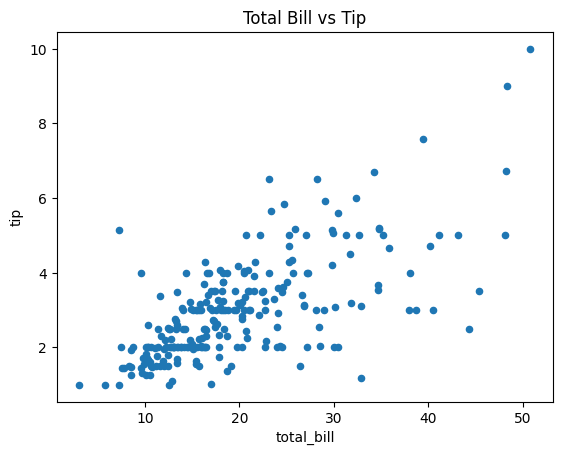

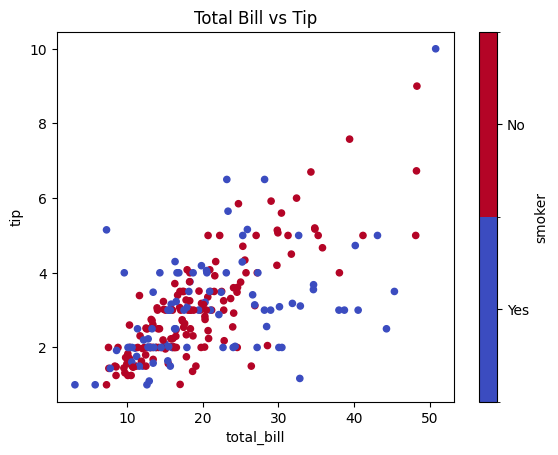

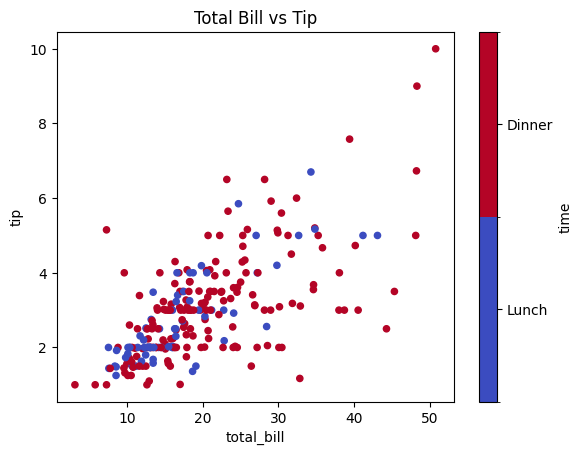

/tmp/ipykernel_1197/1594120549.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tips.groupby('day')['tip'].mean().plot(kind='bar')


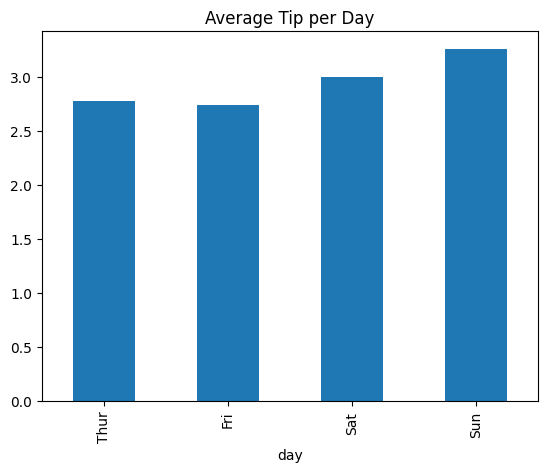

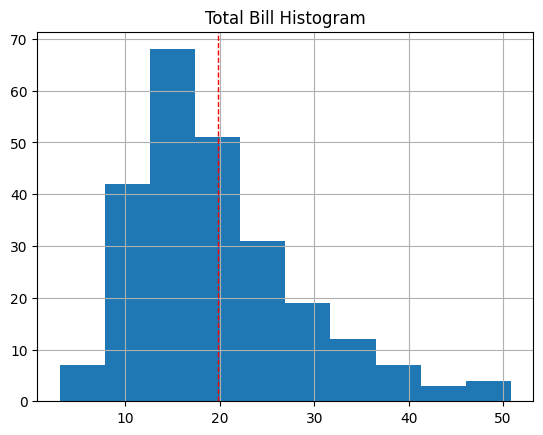

In [19]:
import matplotlib.pyplot as plt

tips = sns.load_dataset('tips')
tips.head()

# a) YOUR CODE HERE: scatter plot total_bill vs tip
tips.plot(x='total_bill', y='tip', kind='scatter')
plt.title('Total Bill vs Tip')
plt.show()

# b) YOUR CODE HERE: same scatter plot colored by 'smoker'
tips.plot (x='total_bill', y='tip', kind='scatter', c='smoker', colormap='coolwarm')
plt.title('Total Bill vs Tip')
plt.show()


# c) YOUR CODE HERE: lmplot of total_bill vs tip, hue='time'
tips.plot(x='total_bill', y='tip', kind='scatter', c='time', colormap='coolwarm')
plt.title('Total Bill vs Tip')
plt.show()

# d) YOUR CODE HERE: bar plot of average tip per day
tips.groupby('day')['tip'].mean().plot(kind='bar')
plt.title('Average Tip per Day')
plt.show()

# e) YOUR CODE HERE: histogram of total_bill with a vertical line at the mean
tips.hist(column='total_bill', bins=10)
plt.axvline(tips['total_bill'].mean(), color='r', linestyle='dashed', linewidth=1)
plt.title('Total Bill Histogram')
plt.show()

---

## Exercise 3: Distributions and multidimensional relationships — Diamonds dataset

Load the built-in `diamonds` dataset from seaborn (it's large, so we take a random sample of 1000 rows to keep the plots fast):

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

This dataset contains information about diamonds: `carat`, `cut`, `color`, `clarity`, `depth`, `table`, `price`, and dimensions `x`, `y`, `z`.

a) Get a statistical summary of the numeric variables with `.describe()`.

b) Create a **histogram** of the `price` variable and mark the mean (dashed line) and the mean ± one standard deviation (two more vertical lines), as done with the `weight` variable of the cars dataset.

c) Create a **joint distribution plot** (`sns.jointplot`) between `carat` and `price`.

d) Create a **pairplot** (`sns.pairplot`) using only the numeric columns `carat`, `depth`, `table`, `price`, colored by the `cut` category with `hue`.

e) Based on the plots above, write one sentence (in a markdown cell or as a Python comment) describing the relationship you observe between `carat` and `price`.

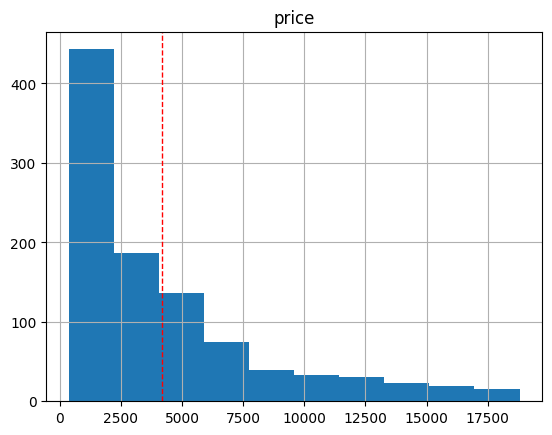

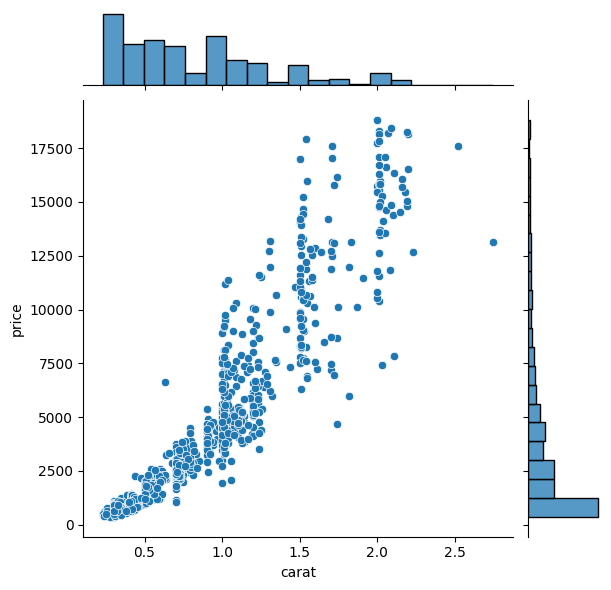

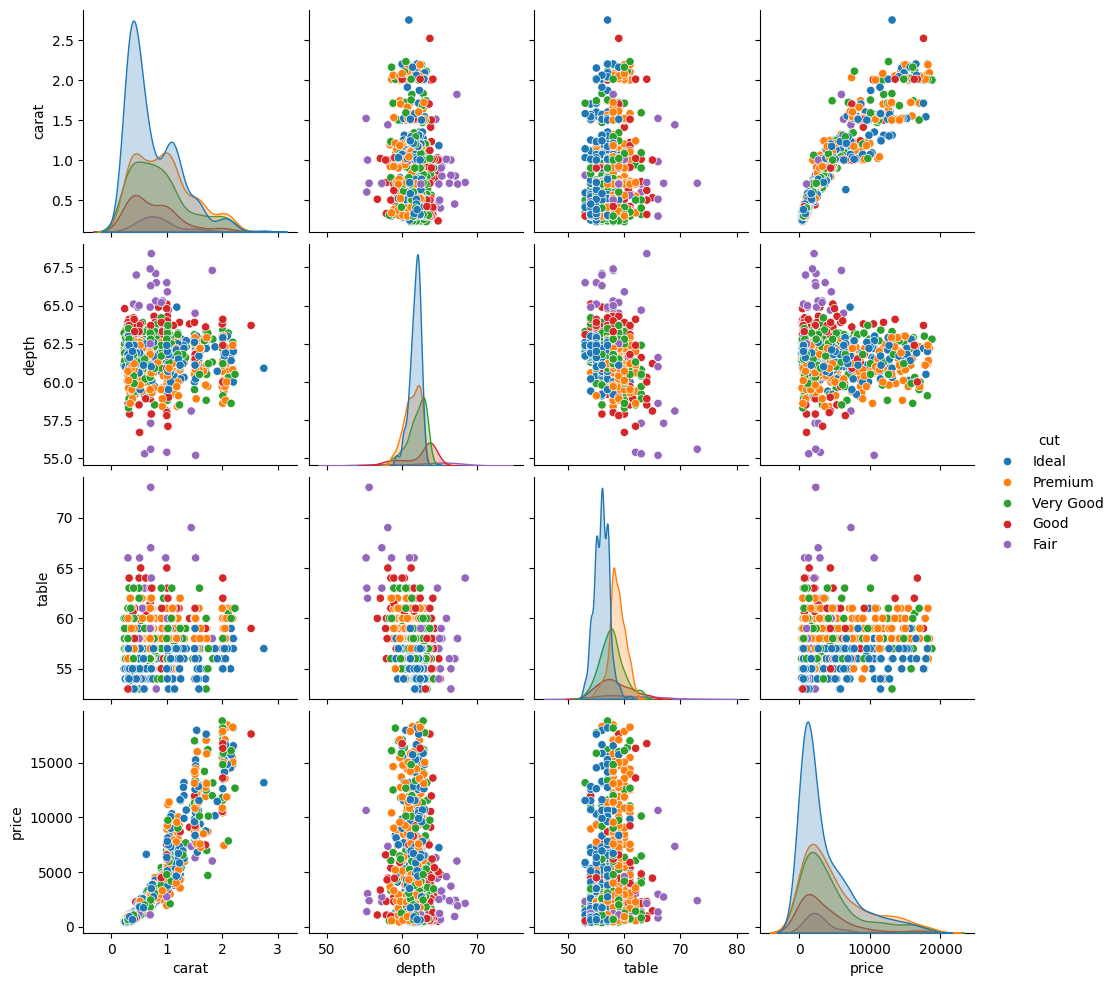

In [32]:
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
diamonds.head()

# a) YOUR CODE HERE: statistical summary
diamonds.describe()

# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines
diamonds.hist(column='price', bins=10)
plt.axvline(diamonds['price'].mean(), color='r', linestyle='dashed', linewidth=1)

# c) YOUR CODE HERE: jointplot between carat and price
sns.jointplot(x='carat', y='price', data=diamonds)
plt.show()

# d) YOUR CODE HERE: pairplot of carat, depth, table, price, hue='cut'
sns.pairplot(data=diamonds, vars=['carat', 'depth', 'table', 'price'], hue='cut')
plt.show()


# e) YOUR CODE HERE (as a comment): describe the relationship between carat and price
# the relation between carat and price is propotional which means when one
# increase the other increase and vise-versa